In [19]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

In [20]:
# Read the data
df = pd.read_csv("Advertising.csv")
df.head()

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [21]:
# Select input and Target as X and y
X = df.iloc[:,:-1].values
y = df.iloc[:, -1].values

In [22]:
# split the data and keep test_size as 0.3 and random_state = 0
# If i run the model and if i want run it again then we write random state and so it will select same data for
# training and testing data again
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [23]:
# import linear regression, make instance and fit the data
from sklearn.linear_model import LinearRegression
reg = LinearRegression()
reg.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [24]:
# Check for the slope and y-intercept
print(reg.coef_)
print(reg.intercept_)

[0.04472952 0.18919505 0.00276111]
2.979067338122631


In [25]:
# print(reg.predict([[6.7]]))

In [26]:
# predict the test set result y_pred
y_pred = reg.predict(X_test)
y_pred

array([16.4080242 , 20.88988209, 21.55384318, 10.60850256, 22.11237326,
       13.10559172, 21.05719192,  7.46101034, 13.60634581, 15.15506967,
        9.04831992,  6.65328312, 14.34554487,  8.90349333,  9.68959028,
       12.16494386,  8.73628397, 16.26507258, 10.27759582, 18.83109103,
       19.56036653, 13.25103464, 12.33620695, 21.30695132,  7.82740305,
        5.80957448, 20.75753231, 11.98138077,  9.18349576,  8.5066991 ,
       12.46646769, 10.00337695, 21.3876709 , 12.24966368, 18.26661538,
       20.13766267, 14.05514005, 20.85411186, 11.0174441 ,  4.56899622])

In [28]:
# Visualising the training set result
# plt.scatter(X_train, y_train, color = "red")
# plt.plot(X_train, reg.predict(X_train), color = 'blue')

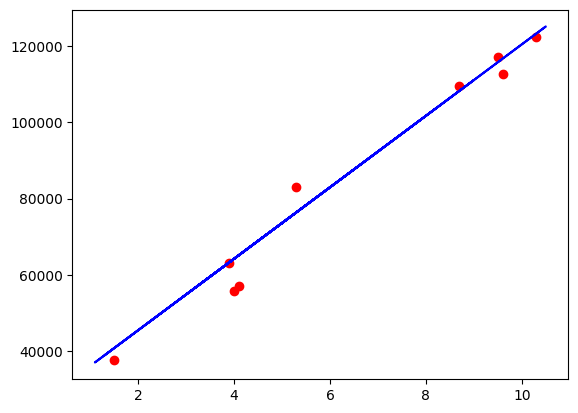

In [ ]:
# Visualising the testing set result
# plt.scatter(X_test, y_test, color = "red")
# plt.plot(X_train, reg.predict(X_train), color = 'blue')

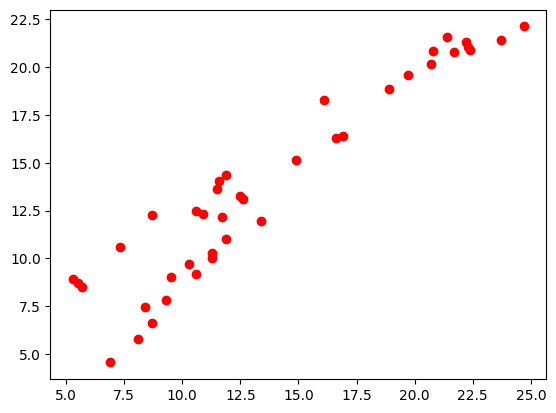

In [29]:
plt.scatter(y_test, y_pred, color = "red")


In [30]:
# evaluation in sklearn.metrics mean_absoloute_error, mean_squared_error, r2_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
MAE = mean_absolute_error(y_test, y_pred)
MSE = mean_squared_error(y_test, y_pred)
R2 = r2_score(y_test, y_pred)
RMSE = np.sqrt(MSE)

In [31]:
# Model Evaluation

print(MAE)
print(MSE)
print(R2)
print(RMSE)

1.4607567168117601
3.174097353976104
0.899438024100912
1.7815996615334502


In [32]:
comp_df = pd.DataFrame({'Actual Salary (y_test)': y_test, 'Predicted Salary (y_pred)': y_pred})
comp_df

,Actual Salary (y_test),Predicted Salary (y_pred)
0,16.9,16.408024
1,22.4,20.889882
2,21.4,21.553843
3,7.3,10.608503
4,24.7,22.112373
5,12.6,13.105592
6,22.3,21.057192
7,8.4,7.461010
8,11.5,13.606346
9,14.9,15.155070


In [ ]:
mean_x = X_train.mean()
mean_y = y_train.mean()

In [ ]:
upp = 0
for i in range(len(X_train)):
    upp += (X_train[i]-mean_x)*(y_train[i]-mean_y)

print(upp[0])

1288462.2523809525


In [ ]:
den = 0
for i in range(len(X_train)):
    den += (X_train[i]-mean_x)**2

print(den[0])

137.65238095238092


In [ ]:
slope = upp/den
print(slope[0])

9360.261286193658


In [ ]:
y_intercept = mean_y - (mean_x*slope)
print(y_intercept[0])

26777.39134119761


In [ ]:
reg.coef_

array([9360.26128619])

In [40]:
adj_r2 = 1 - (1-R2)*(X_test.shape[0]-1)/(X_test.shape[0]-X_test.shape[1]-1)
adj_r2

0.8910578594426547

In [41]:
R2

0.899438024100912